## **1.Theoretical Foundations**

### **1.1 The Universal Approximation Theorem (UAT)**

a) In 2-3 lines, state the Universal Approximation Theorem for a single-hidden-layer feedforward neural network.

b) Briefly discuss the limitations of the UAT. What does it guarantee, and what does it not guarantee about network training, architecture, or efficiency?

### **Answer**

**a)** A single-hidden-layer feedforward neural network passes the inputs X through multiple neurons and feeds them into a nonlinear activation function. These neurons will create a bunch of different shifted and scaled functions, whose weighted combination can approximate any continuous functions on a compact domain.

**b)** The UAT can guarantee the existence of neural network can approximate the continuous functions. But it doesn’t guarantee the training could find the required weights and bias, and the necessary number of neurons as well as the layers of neurons. It also cannot provide guarantee of efficiency, whether less neurons, parameters and training data could achieve the same approximation.

### **1.2 Bernstein Polynomials and a ReLU Network**

The Bernstein polynomial of degree $n$ for $f$ on $[0, 1]$ is
$$
B_n(fx)=\sum_{k=0}^{n}
f\left(\frac{k}{n}\right)
\binom{n}{k}x^k(1-x)^{n-k}.
$$

Take $f_1(x)=sin(\pi x)$ and $f_2(x)=|x-\frac{1}{2}|$

a) For each function, plot Bnf against f for n = 4, 16, 64, 256 and report the largest gap maxx |f(x) − Bnf(x)| for each n.

b) Repeat with a one-hidden-layer ReLU network of width 4, 16, 64, 256, trained on 200 evenly spaced samples of f.

c) Which function does each representation handle better, and why?

### **Answer**

**a)** 	For f_1 (x)=sin⁡(πx), the largest gap max_x |f(x)-B_n f(x)|, for n=4, 16, 64, 256 is 0.2714, 0.0743, 0.0191, 0.0048

For f_2 (x)=|x-0.5|, the largest gap max_x |f(x)-B_n f(x)|, for n=4, 16, 64, 256 is 0.1870, 0.0977, 0.0492, 0.0244


[0.27144612 0.07432335 0.01909382 0.00480757]
[0.18699988 0.09769059 0.04917447 0.02441225]


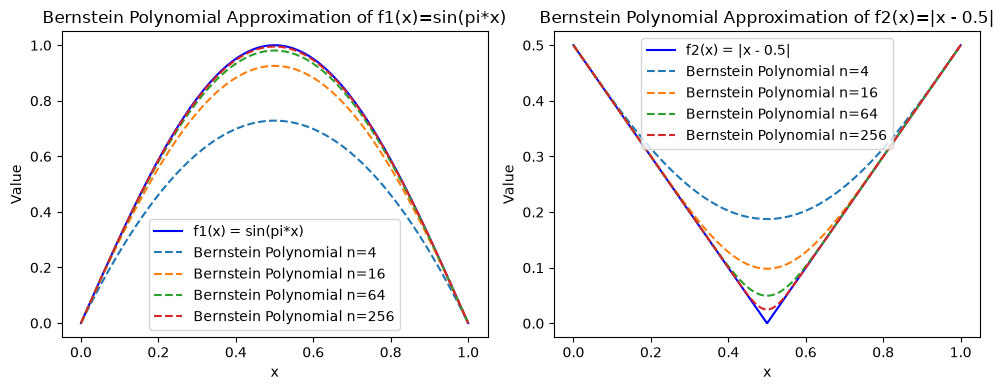

In [2]:
# SCI-ML HW#00: MLP function approximation

# 1.2 Bernstein Polynomials and a ReLU Network
#a)

import numpy as np
import matplotlib.pyplot as plt
import math

x = np.linspace(0, 1, 1000)
f1 = lambda x: np.sin(np.pi * x)
f2 = lambda x: np.abs(x - 0.5)

Bnf1 = []
Bnf2 = []

n = [4, 16, 64, 256]
for n_i in n:
    Bnf1_i = np.zeros_like(x)
    Bnf2_i = np.zeros_like(x)
    for k in range(n_i + 1):
        Bnf1_i += f1(k / n_i) * (math.comb(n_i, k) * (x ** k) * ((1 - x) ** (n_i - k)))
        Bnf2_i += f2(k / n_i) * (math.comb(n_i, k) * (x ** k) * ((1 - x) ** (n_i - k)))
    Bnf1.append(Bnf1_i)
    Bnf2.append(Bnf2_i)

print(np.abs(np.array(Bnf1) - f1(x)).max(1))
print(np.abs(np.array(Bnf2) - f2(x)).max(1))

plt.figure(figsize=(10, 4))
plt.subplot(1, 2, 1)
plt.plot(x, f1(x), label='f1(x) = sin(pi*x)', color='blue')
for n_i in n:
    plt.plot(x, Bnf1[n.index(n_i)], label=f'Bernstein Polynomial n={n_i}', linestyle='--')
plt.title('Bernstein Polynomial Approximation of f1(x)=sin(pi*x)')
plt.xlabel('x')     
plt.ylabel('Value')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(x, f2(x), label='f2(x) = |x - 0.5|', color='blue')
for n_i in n:
    plt.plot(x, Bnf2[n.index(n_i)], label=f'Bernstein Polynomial n={n_i}', linestyle='--')
plt.title('Bernstein Polynomial Approximation of f2(x)=|x - 0.5|')
plt.xlabel('x')
plt.ylabel('Value')
plt.legend()
plt.tight_layout()
plt.show()

**b)** One-hidden-layer ReLU network

For f_1 (x)=sin⁡(πx), the largest gap between prediction and f_1 (x), for n=4, 16, 64, 256 is 0.0651, 0.0257, 0.0050, 0.0012

For f_2 (x)=|x-0.5|, the largest gap max_x |f(x)-B_n f(x)|, for n=4, 16, 64, 256 is 0.0016, 0.0022, 0.0018, 0.0024


n=4: sin loss = 0.06509595222523967
n=4: abs loss = 0.0016354095932837875
n=16: sin loss = 0.025707977026751316
n=16: abs loss = 0.002284988462626647
n=64: sin loss = 0.005002144212492343
n=64: abs loss = 0.0018183683787282856
n=256: sin loss = 0.001210056840316387
n=256: abs loss = 0.002457673363089219


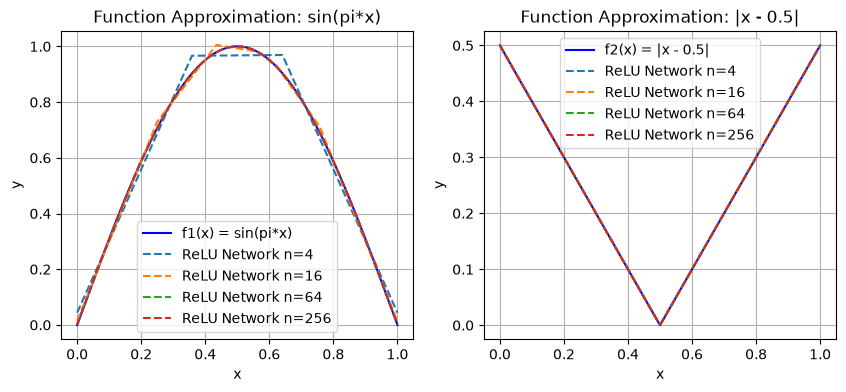

In [3]:
# SCI-ML HW#00: MLP function approximation

# 1.2 Bernstein Polynomials and a ReLU Network
#b) use a single neural network

import numpy as np
import matplotlib.pyplot as plt
import torch
import os
os.environ["KMP_DUPLICATE_LIB_OK"] = "TRUE"

class ReLU_Net(torch.nn.Module):

    def __init__(self, hidden_size=10): 
        super(ReLU_Net, self).__init__()
        self.hidden = torch.nn.Linear(1, hidden_size)
        #torch.nn.init.normal_(self.hidden.weight, mean=0.0, std=1.0)
        with torch.no_grad():
            kinks = torch.rand(hidden_size)     # kink positions in [0, 1]
            self.hidden.bias.copy_(-self.hidden.weight.squeeze(1) * kinks)
        self.output = torch.nn.Linear(hidden_size, 1)
        #torch.nn.init.normal_(self.output.weight, mean=0.0, std=0.1)
        #torch.nn.init.zeros_(self.output.bias)
        self.activation = torch.nn.ReLU()

    def forward(self, x):
        x = self.hidden(x)
        x = self.activation(x)
        x = self.output(x)
        return x

def train_network(model, x_train, y_train, epochs=3000, learning_rate=0.01):
    optimizer = torch.optim.Adam(model.parameters(), lr=learning_rate)
    loss_fn = torch.nn.MSELoss()
    losses = []
    for epoch in range(epochs):
        optimizer.zero_grad()
        y_pred = model.forward(x_train)
        loss = loss_fn(y_pred, y_train)
        loss.backward()
        optimizer.step()
        losses.append(loss.item())    
    return losses

x_test = np.linspace(0, 1, 1000)
x_test_tensor = torch.tensor(x_test, dtype=torch.float32).reshape(-1, 1)
x_train_np = np.linspace(0, 1, 200)
y_train1 = np.sin(np.pi * x_train_np)
y_train2 = np.abs(x_train_np - 0.5)

f1 = lambda x: np.sin(np.pi * x)
f2 = lambda x: np.abs(x - 0.5)

fig, (ax1, ax2) = plt.subplots(1,2, figsize=(10, 4))
ax1.set_title('Function Approximation: sin(pi*x)')
ax2.set_title('Function Approximation: |x - 0.5|')

ax1.plot(x_test, f1(x_test), label='f1(x) = sin(pi*x)', color='blue')
ax2.plot(x_test, f2(x_test), label='f2(x) = |x - 0.5|', color='blue')

for n_i in [4, 16, 64, 256]:
    x_train = torch.tensor(x_train_np, dtype=torch.float32).reshape(-1, 1)
    y1_train = torch.tensor(f1(x_train_np), dtype=torch.float32).reshape(-1, 1)
    y2_train = torch.tensor(f2(x_train_np), dtype=torch.float32).reshape(-1, 1)

    model1 = ReLU_Net(hidden_size=n_i)
    model2 = ReLU_Net(hidden_size=n_i)
    losses1 = train_network(model1, x_train, y1_train, epochs=3000, learning_rate=0.002)
    losses2 = train_network(model2, x_train, y2_train, epochs=3000, learning_rate=0.002)

    y1_pred = model1.forward(x_test_tensor).detach().numpy()
    print(f'n={n_i}: sin loss = {np.abs(y1_pred - f1(x_test).reshape(-1, 1)).max()}')
    ax1.plot(x_test_tensor.numpy(), y1_pred, label=f'ReLU Network n={n_i}', linestyle='--')
    y2_pred = model2.forward(x_test_tensor).detach().numpy()
    print(f'n={n_i}: abs loss = {np.abs(y2_pred - f2(x_test).reshape(-1, 1)).max()}')
    ax2.plot(x_test_tensor.numpy(), y2_pred, label=f'ReLU Network n={n_i}', linestyle='--')

ax1.set_xlabel('x')
ax1.set_ylabel('y')
ax1.set_title('Function Approximation: sin(pi*x)')
ax1.legend()
ax1.grid(True)

ax2.set_xlabel('x')
ax2.set_ylabel('y')
ax2.set_title('Function Approximation: |x - 0.5|')
ax2.legend()
ax2.grid(True)

plt.show()

c) 	For function f_1 (x)=sin⁡(πx), the Berstein Polynomial can handle better, because for n≥4 it is smooth and could handle sine function generally better. However, for function f_2 (x)=|x-0.5|, which has a corner, the ReLU works better than Bernstein Polynomial, because from the ReLU function a hat function can be formed, which could handle functions with corner better than polynomial functions.

### **1.3 Derivatives of Sigmoid and ReLU**

a) For $σ(z) = (1 + e^{−z})^{−1}$, derive $σ^{'}(z)$ by hand and show that $σ^{'}(z) = σ(z) (1 − σ(z))$.

b) For ReLU(z) = max(0, z), write the derivative for z < 0 and for z > 0. What happens at z = 0?

c) Plot σ, σ′, ReLU, and ReLU′ on [−5, 5]. Where is σ′ small, and what does that do to a gradient that passes through such a unit during backpropagation?

### **Answer**

**a)** $$σ(z) = \frac{1}{1+e^{-z}}$$

$$
\frac{dσ(z)}{dz}=-\frac{1}{(1+e^{-z})^2}\cdot e^{-z} \cdot (-1)=\frac{e^{-z}}{(1+e^{-z})^2}=\frac{1}{1+e^{-z}}\cdot \frac{e^{-z}}{1+e^{-z}}=σ(z) \cdot \frac{1+e^{-z}-1}{1+e^{-z}}=σ(z)\cdot (1-σ(z))
$$

**b)** $ReLU(z)=max(0,z)$

$$\frac{dReLU(z)}{dz}=max(0,\frac{z}{|z|})=\begin{cases}
0, & z < 0, \\
1, & z > 0.
\end{cases}$$

At $z=0$, the derivative of function ReLU jumps from 0 to 1.

**c)** when $|x|≥3$, $σ^{'}$ becomes small, the gradient passes through $σ^{'}$ will shrinks and becomes close to 0. This could lead to a very slow update of weights and inefficient learning.

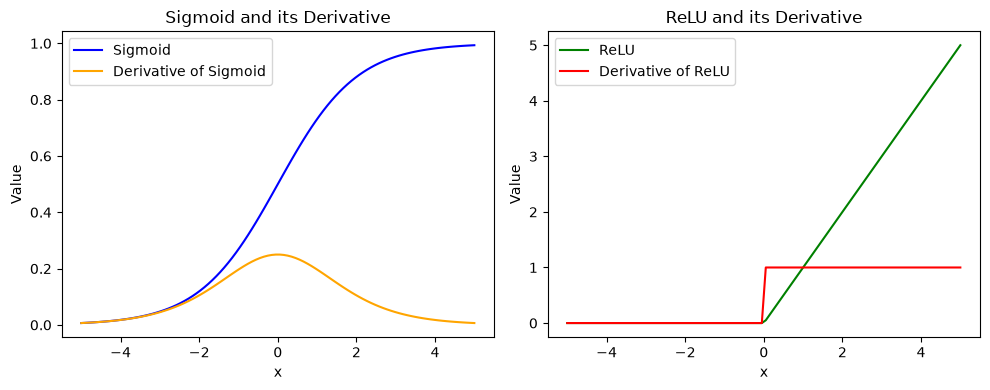

In [4]:
# SCI-ML HW#00: MLP function approximation

# 1.3 Deriatives of Sigmoid and ReLU
#c)
import numpy as np
import matplotlib.pyplot as plt

x = np.linspace(-5, 5, 100)
sigmoid = 1 / (1 + np.exp(-x))
deriative_sigmoid = sigmoid * (1 - sigmoid)

ReLU = np.maximum(0, x)
derivative_ReLU = (x > 0).astype(float)

plt.figure(figsize=(10, 4))
plt.subplot(1, 2, 1)
plt.plot(x, sigmoid, label='Sigmoid', color='blue')
plt.plot(x, deriative_sigmoid, label='Derivative of Sigmoid', color='orange')
plt.title('Sigmoid and its Derivative') 

plt.xlabel('x')
plt.ylabel('Value')     
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(x, ReLU, label='ReLU', color='green')
plt.plot(x, derivative_ReLU, label='Derivative of ReLU', color='red')
plt.title('ReLU and its Derivative')
plt.xlabel('x')     
plt.ylabel('Value')
plt.legend()
plt.tight_layout()

plt.show()

## **2. Computational Experiments: Function Approximation**

### **2.1 Approximating a Discontinuous Function**

This problem explores the challenge of approximating non-smooth functions. Consider the Heaviside step function on the interval $x ∈ [0, 1]$:

$$
H(x)=\begin{cases}
0 & x<0.5 \\
1 & x\ge{0.5}
\end{cases}
$$
a) Using a single hidden layer MLP with 50 neurons and a ‘tanh‘ activation, train the network to approximate $H(x)$.

b) Plot the learned function $\hat{u}(x)$ against the true function $H(x)$. Describe the behavior around the discontinuity at $x=0.5$. Does it resemble the Gibbs phenomenon?

c) Experiment to improve the approximation by independently:

    • Increasing the hidden layer width (e.g., to 200, then 500 neurons).
    • Increasing the network depth (e.g., 3 hidden layers of 50 neurons each).
    • Changing the activation function to ReLU.
    • Try different loss functions

d) **Analysis:** Why does a ‘tanh‘-based network struggle with discontinuities? Which modification produced the best result and why? Relate your findings to the fact that compositions of ‘tanh‘ are $C^{∞}$, while ReLU networks are piecewise linear.

### **Answer**

**a)**

In [26]:
# SCI-ML HW#00: MLP function approximation

# 2.1 Approximating a discoutinuous function


import numpy as np
import matplotlib.pyplot as plt
import torch
import os

class SingleLayer_Net(torch.nn.Module):

    def __init__(self, hidden_size=50): 
        super(SingleLayer_Net, self).__init__()
        self.hidden_1 = torch.nn.Linear(1, hidden_size)
        self.output = torch.nn.Linear(hidden_size, 1)
        self.activation = torch.nn.Tanh() 

    def forward(self, x):
        x = self.hidden_1(x)
        x = self.activation(x)
        x = self.output(x)
        return x

def train_network(model, x_train, y_train, epochs=3000, learning_rate=0.01):
    optimizer = torch.optim.Adam(model.parameters(), lr=learning_rate)
    loss_fn = torch.nn.MSELoss()
    losses = []
    for epoch in range(epochs):
        optimizer.zero_grad()
        y_pred = model.forward(x_train)
        loss = loss_fn(y_pred, y_train)
        loss.backward()
        optimizer.step()
        losses.append(loss.item())
    return losses

x_train = np.linspace(-1, 1, 500)
y_train = np.where(x_train < 0.5, 0, 1)

x_test = np.linspace(-1, 1, 1000)
y_test = np.where(x_test < 0.5, 0, 1)

x_train_tensor = torch.tensor(x_train.reshape(-1, 1), dtype=torch.float32)
y_train_tensor = torch.tensor(y_train.reshape(-1, 1), dtype=torch.float32)
x_test_tensor = torch.tensor(x_test.reshape(-1, 1), dtype=torch.float32)
y_test_tensor = torch.tensor(y_test.reshape(-1, 1), dtype=torch.float32)

model = SingleLayer_Net(hidden_size=50)
_=train_network(model, x_train_tensor, y_train_tensor, epochs=5000, learning_rate=0.005)

**b)** Plot the learned function through MLP with 50 neurons against the true function

Near the jump the single hidden layer MLP approximation undershoots below the lower target and overshoots above the upper target. This happens because the network uses a weighted combination of smooth tanh function to fit a jump while minimizing the mean square error over the entire domain. This is not a Gibbs Phenomenon. This may depend on the neural network’s architecture, loss function etc. This behavior may disappear after changing or optimizing the model.

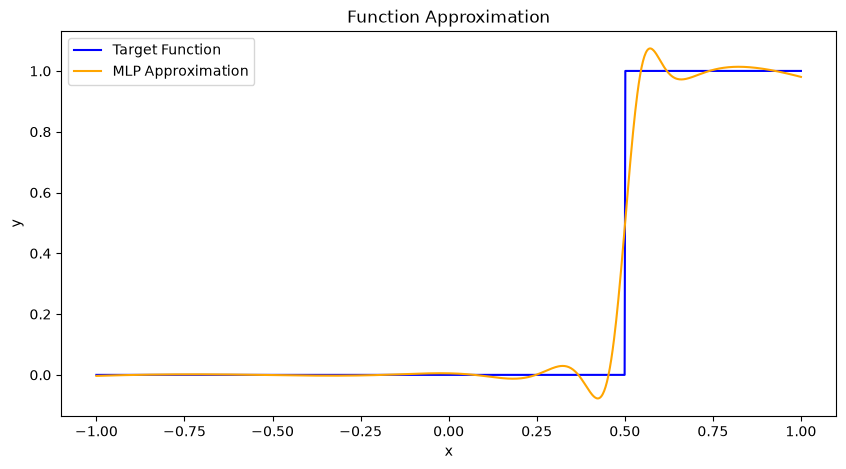

In [27]:
fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(x_test, y_test, label='Target Function', color='blue')
y_pred = model.forward(x_test_tensor).detach().numpy()
ax.plot(x_test_tensor.numpy(), y_pred, label='MLP Approximation', color='orange')
ax.legend()
ax.set_xlabel('x')
ax.set_ylabel('y')
ax.set_title('Function Approximation')
plt.show()

**c)** 

    • Increase the 1 hidden layer width to 200 neurons

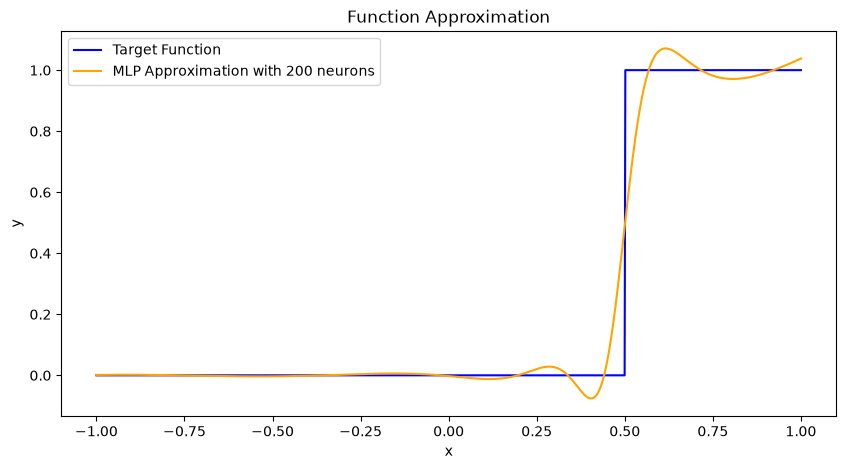

In [25]:
model = SingleLayer_Net(hidden_size=200)
_=train_network(model, x_train_tensor, y_train_tensor, epochs=5000, learning_rate=0.005)
fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(x_test, y_test, label='Target Function', color='blue')
y_pred = model.forward(x_test_tensor).detach().numpy()
ax.plot(x_test_tensor.numpy(), y_pred, label='MLP Approximation with 200 neurons', color='orange')
ax.legend()
ax.set_xlabel('x')
ax.set_ylabel('y')
ax.set_title('Function Approximation')
plt.show()

    • Increase the 1 hidden layer width to 500 neurons

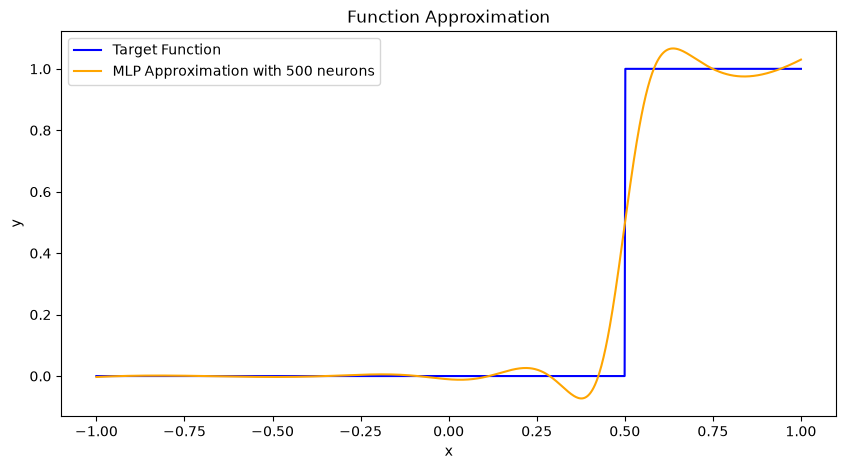

In [24]:
model = SingleLayer_Net(hidden_size=500)
_=train_network(model, x_train_tensor, y_train_tensor, epochs=5000, learning_rate=0.005)
fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(x_test, y_test, label='Target Function', color='blue')
y_pred = model.forward(x_test_tensor).detach().numpy()
ax.plot(x_test_tensor.numpy(), y_pred, label='MLP Approximation with 500 neurons', color='orange')
ax.legend()
ax.set_xlabel('x')
ax.set_ylabel('y')
ax.set_title('Function Approximation')
plt.show()

    • Increase the hidden layer depth to 3 layers of 50 neurons each

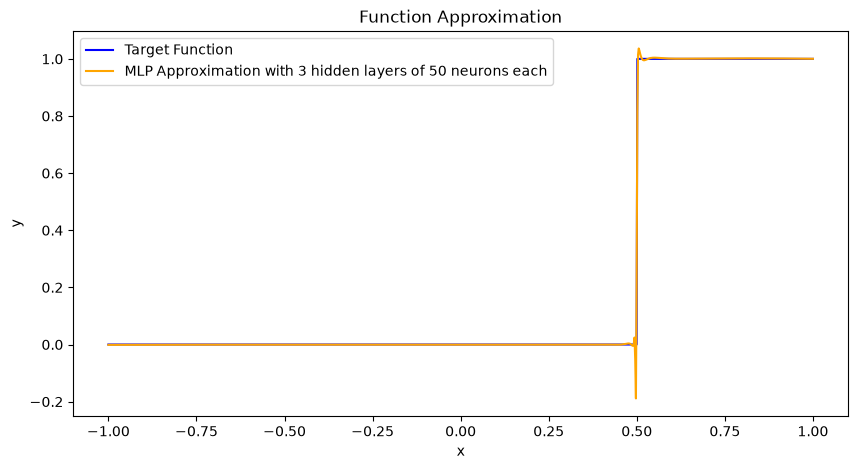

In [23]:
import numpy as np
import matplotlib.pyplot as plt
import torch
import os

class MLP(torch.nn.Module):

    def __init__(self, hidden_size=50, num_layers=1): 
        super(MLP, self).__init__()
        self.hidden = torch.nn.Linear(1, hidden_size)
        self.activation = torch.nn.Tanh()
        self.output = torch.nn.Linear(hidden_size, 1)
        layer = [self.hidden, self.activation]
        for _ in range(num_layers - 1):
            layer += [torch.nn.Linear(hidden_size, hidden_size), self.activation]
        layer.append(self.output)
        self.model = torch.nn.Sequential(*layer)

    def forward(self, x):
        return self.model(x)

model = MLP(hidden_size=50, num_layers=3)
_=train_network(model, x_train_tensor, y_train_tensor, epochs=5000, learning_rate=0.005)
fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(x_test, y_test, label='Target Function', color='blue')
y_pred = model.forward(x_test_tensor).detach().numpy()
ax.plot(x_test_tensor.numpy(), y_pred, label='MLP Approximation with 3 hidden layers of 50 neurons each', color='orange')
ax.legend()
ax.set_xlabel('x')
ax.set_ylabel('y')
ax.set_title('Function Approximation')
plt.show()

    • Change the activation function to ReLU with one hidden layer of 50 neurons

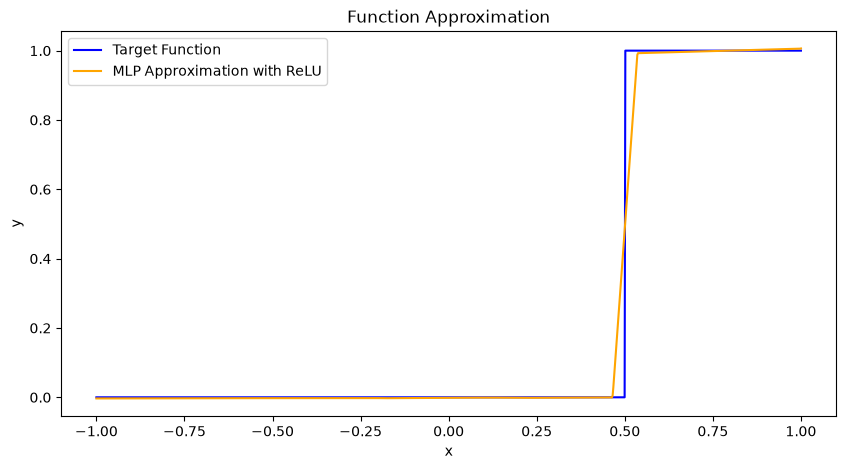

In [30]:
import numpy as np
import matplotlib.pyplot as plt
import torch
import os

class SingleLayer_ReLU(torch.nn.Module):

    def __init__(self, hidden_size=50): 
        super(SingleLayer_ReLU, self).__init__()
        self.hidden_1 = torch.nn.Linear(1, hidden_size)
        self.output = torch.nn.Linear(hidden_size, 1)
        self.activation = torch.nn.ReLU() 

    def forward(self, x):
        x = self.hidden_1(x)
        x = self.activation(x)
        x = self.output(x)
        return x

model = SingleLayer_ReLU(hidden_size=50)
_=train_network(model, x_train_tensor, y_train_tensor, epochs=5000, learning_rate=0.005)
fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(x_test, y_test, label='Target Function', color='blue')
y_pred = model.forward(x_test_tensor).detach().numpy()
ax.plot(x_test_tensor.numpy(), y_pred, label='MLP Approximation with ReLU', color='orange')
ax.legend()
ax.set_xlabel('x')
ax.set_ylabel('y')
ax.set_title('Function Approximation')
plt.show()

    • Use Mean absolute error function with 1 hidden layer with 50 neurons

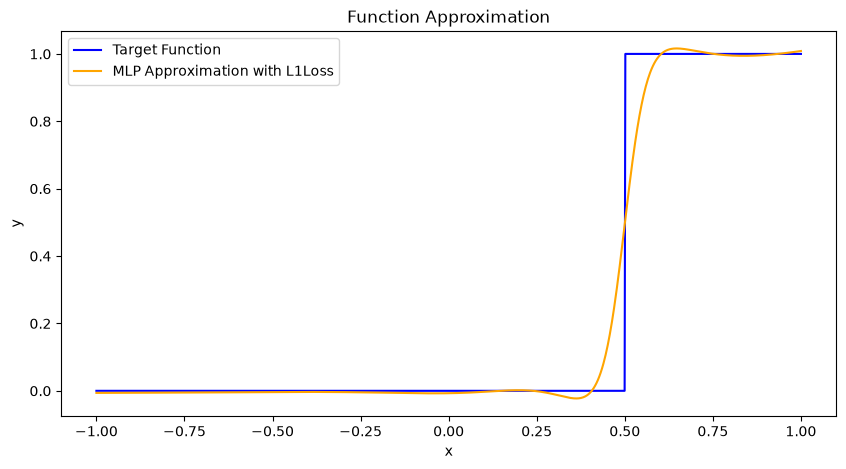

In [31]:
import numpy as np
import matplotlib.pyplot as plt
import torch
import os

class SingleLayer_ReLU(torch.nn.Module):

    def __init__(self, hidden_size=50): 
        super(SingleLayer_ReLU, self).__init__()
        self.hidden_1 = torch.nn.Linear(1, hidden_size)
        self.output = torch.nn.Linear(hidden_size, 1)
        self.activation = torch.nn.ReLU() 

    def forward(self, x):
        x = self.hidden_1(x)
        x = self.activation(x)
        x = self.output(x)
        return x

def train_network(model, x_train, y_train, epochs=3000, learning_rate=0.01):
    optimizer = torch.optim.Adam(model.parameters(), lr=learning_rate)
    loss_fn = torch.nn.L1Loss()
    losses = []
    for epoch in range(epochs):
        optimizer.zero_grad()
        y_pred = model.forward(x_train)
        loss = loss_fn(y_pred, y_train)
        loss.backward()
        optimizer.step()
        losses.append(loss.item())
    return losses

x_train = np.linspace(-1, 1, 500)
y_train = np.where(x_train < 0.5, 0, 1)

x_test = np.linspace(-1, 1, 1000)
y_test = np.where(x_test < 0.5, 0, 1)

x_train_tensor = torch.tensor(x_train.reshape(-1, 1), dtype=torch.float32)
y_train_tensor = torch.tensor(y_train.reshape(-1, 1), dtype=torch.float32)
x_test_tensor = torch.tensor(x_test.reshape(-1, 1), dtype=torch.float32)
y_test_tensor = torch.tensor(y_test.reshape(-1, 1), dtype=torch.float32)

model = SingleLayer_Net(hidden_size=50)
_=train_network(model, x_train_tensor, y_train_tensor, epochs=5000, learning_rate=0.005)

fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(x_test, y_test, label='Target Function', color='blue')
y_pred = model.forward(x_test_tensor).detach().numpy()
ax.plot(x_test_tensor.numpy(), y_pred, label='MLP Approximation with L1Loss', color='orange')
ax.legend()
ax.set_xlabel('x')
ax.set_ylabel('y')
ax.set_title('Function Approximation')
plt.show()

**d) Analysis:** tanh is a smooth function, whose derivative is also continuous. So, a finite sum of tanh units is also smooth, which cannot reproduce a corner or jump exactly. It replaces the non-smooth feature with a steep but smooth transition with overshoot and undershoot. So, it can struggle with discontinuities. Changing the activation function to ReLU. ReLU is linear at certain parts, which could help build a hat function. Therefore, a few ReLU units could form a steep ramp with sharp corner compared to tanh function

## **3. Computational Learning**

This section explores how to solve complex problems by breaking them into simpler, modular components that can be learned separately and then combined.

### **3.1 Learning and Composing Multi-Scale Functions**

Consider the function $h(x) = flinear(x) + fhigh(x)$ on the interval $x ∈ [0, 1]$, where:

    • $f_{linear}(x) = 1 + 2x$ (a simple linear trend)
    • $f_{high}(x) = 0.5 cos(20πx)$ (a high-frequency component)

### **Part 1: Learning the High-Frequency Component**

To understand the challenge, first focus solely on approximating $f_{high}(x)$.

a) Train MLPs of increasing depth (1, 2, 3, and 4 hidden layers) to learn $f_{high}(x)$.

b) Plot the results on a 2x2 grid to visually demonstrate how approximation quality improves with depth. Explain this result in the context of spectral bias.

### **Part 2: Composition by “Stitching” Networks**

Now, we will tackle the full problem h(x) using a “divide and conquer” strategy.

a) **Modular Training:**

    • Train a simple, shallow network, Nlinear, to learn $f_{linear}(x)$.
    • Train a separate, deep network, Nhigh, to learn $f_{high}(x)$.
    
b) **Manual Composition:** The final stitched model is formed by adding the outputs of the two trained networks:
$$\hat{h}_{stitched}(x) = N_{linear}(x) + N_{high}(x)
$$
Implement this composition in code.

c) **Comparison & Analysis:** Train a single, deep end-to-end network to learn $h(x)$ directly. Create a side-by-side plot comparing the result of your stitched model against the end-to-end model. For clarity, zoom in on the interval $x ∈ [0.2, 0.8]$ for one of your plots. Discuss the results. Which approach is more effective and why?

### **Answer**

### **Part 1**

**a)** Train MLPs of increasing depth (1, 2, 3, and 4 hidden layers) to learn $f_{high}(x)$.

In [37]:
import numpy as np
import matplotlib.pyplot as plt
import torch
import os

class MLP(torch.nn.Module):

    def __init__(self, hidden_size=50, num_layers=1): 
        super(MLP, self).__init__()
        self.hidden = torch.nn.Linear(1, hidden_size)
        self.activation = torch.nn.Tanh()
        self.output = torch.nn.Linear(hidden_size, 1)
        layer = [self.hidden, self.activation]
        for _ in range(num_layers - 1):
            layer += [torch.nn.Linear(hidden_size, hidden_size), self.activation]
        layer.append(self.output)
        self.model = torch.nn.Sequential(*layer)

    def forward(self, x):
        return self.model(x)

def train_network(model, x_train, y_train, epochs=3000, learning_rate = 0.01):
    optimizer = torch.optim.Adam(model.parameters(), lr=learning_rate)
    loss_fn = torch.nn.MSELoss()
    losses = []
    for epoch in range(epochs):
        optimizer.zero_grad()
        y_pred = model.forward(x_train)
        loss = loss_fn(y_pred, y_train)
        loss.backward()
        optimizer.step()
        losses.append(loss.item())
        #if epoch % 1000 == 0:
        #    print(f'Epoch{epoch+1}/{epochs}, Loss:{loss.item():.6f}')
    return losses

x_train = np.linspace(0,1,400)
x_train_tensor = torch.tensor(x_train.reshape(-1,1), dtype = torch.float32)

y_high = lambda x: 0.5*np.cos(20*np.pi*x)
y_train = y_high(x_train)
y_train_tensor = torch.tensor(y_train.reshape(-1,1), dtype = torch.float32)

x_train_test = np.linspace(0,1,2000)
x_train_test_tensor = torch.tensor(x_train_test.reshape(-1,1), dtype = torch.float32)

**b)**

The MLP, using a smooth activation function tanh, is trained by gradient descent starts learning low frequencies before high-frequency variation. With only 1 layer of neurons with tanh activation function and MSE Loss function, it tends to predict the mean value of the target function with high frequency. Increasing the number of layers to 2 could improve the approximation, because each additional neuron could contribute to adding another shifted and scaled tanh function to construct the high-frequency peaks. 

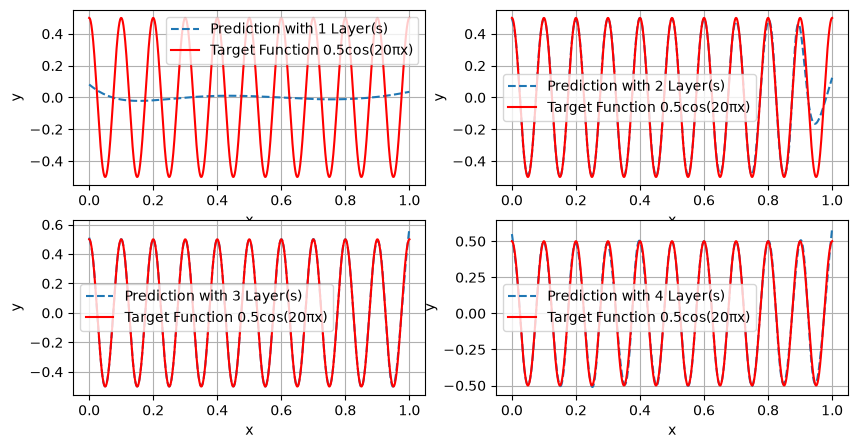

In [38]:
fig, ([ax1, ax2], [ax3, ax4]) = plt.subplots(2,2, figsize=(10,5))
ax = [ax1, ax2, ax3, ax4]
epochs = [10000, 15000, 30000, 30000]
for i,j in [(1,1), (2,2), (3,3), (4,4)]:
    #print(f'Training MLP with {j} Layers\n')
    model = MLP(hidden_size=50, num_layers=j)
    loss = train_network(model, x_train_tensor, y_train_tensor, epochs=epochs[j-1], learning_rate = 0.001)
    #print(f'Training Loss for {j} Layers: {loss[-1]:.6f}\n')
    y_pred = model.forward(x_train_test_tensor).detach().numpy()
    #print(f'Test loss for {j} Layers: {np.mean((y_pred - y_high(x_train_test).reshape(-1,1))**2):.6f}\n')
    
    ax[i-1].plot(x_train_test, y_pred, label=f'Prediction with {j} Layer(s)', linestyle='--')
    ax[i-1].plot(x_train_test, y_high(x_train_test), label='Target Function 0.5cos(20πx)', color='red')
    ax[i-1].legend()
    ax[i-1].set_xlabel('x')
    ax[i-1].set_ylabel('y')
    ax[i-1].grid(True)

plt.show()

### **Part 2**

**a)** Modular Training

In [42]:
# SCI-ML HW#00: MLP function approximation

# 3.1 Learning and Composing Multi-Scale Functions
# Part 2 


import numpy as np
import matplotlib.pyplot as plt
import torch
import os

class MLP_ReLU(torch.nn.Module):

    def __init__(self, hidden_size=50, num_layers=1): 
        super(MLP_ReLU, self).__init__()
        self.hidden = torch.nn.Linear(1, hidden_size)
        self.activation = torch.nn.ReLU()
        self.output = torch.nn.Linear(hidden_size, 1)
        layer = [self.hidden, self.activation]
        for _ in range(num_layers - 1):
            layer += [torch.nn.Linear(hidden_size, hidden_size), self.activation]
        layer.append(self.output)
        self.model = torch.nn.Sequential(*layer)

    def forward(self, x):
        return self.model(x)

class MLP_Tanh(torch.nn.Module):

    def __init__(self, hidden_size=50, num_layers=1): 
        super(MLP_Tanh, self).__init__()
        self.hidden = torch.nn.Linear(1, hidden_size)
        self.activation = torch.nn.Tanh()
        self.output = torch.nn.Linear(hidden_size, 1)
        layer = [self.hidden, self.activation]
        for _ in range(num_layers - 1):
            layer += [torch.nn.Linear(hidden_size, hidden_size), self.activation]
        layer.append(self.output)
        self.model = torch.nn.Sequential(*layer)

    def forward(self, x):
        return self.model(x)

def train_network(model, x_train, y_train, epochs=3000, learning_rate = 0.01):
    optimizer = torch.optim.Adam(model.parameters(), lr=learning_rate)
    loss_fn = torch.nn.MSELoss()
    losses = []
    for epoch in range(epochs):
        optimizer.zero_grad()
        y_pred = model.forward(x_train)
        loss = loss_fn(y_pred, y_train)
        loss.backward()
        optimizer.step()
        losses.append(loss.item())
        #if epoch % 1000 == 0:
        #    print(f'Epoch{epoch+1}/{epochs}, Loss:{loss.item():.6f}')
    return losses

x_train = np.linspace(0,1,1000)
x_train_tensor = torch.tensor(x_train.reshape(-1,1), dtype = torch.float32)

y_linear = lambda x: 1+2*x
y_train_linear = y_linear(x_train)
y_train_linear_tensor = torch.tensor(y_train_linear.reshape(-1,1), dtype = torch.float32)

y_high = lambda x: 0.5*np.cos(20*np.pi*x)
y_train_high = y_high(x_train)
y_train_high_tensor = torch.tensor(y_train_high.reshape(-1,1), dtype = torch.float32)

y_final = lambda x: 1+2*x + 0.5*np.cos(20*np.pi*x)
y_train_final = y_final(x_train)
y_train_final_tensor = torch.tensor(y_train_final.reshape(-1,1), dtype = torch.float32)

model_relu = MLP_ReLU(hidden_size=50, num_layers=1)
model_tanh = MLP_Tanh(hidden_size=50, num_layers=3)

loss_relu = train_network(model_relu, x_train_tensor, y_train_linear_tensor, epochs=3000, learning_rate = 0.001)
loss_tanh = train_network(model_tanh, x_train_tensor, y_train_high_tensor, epochs=20000, learning_rate = 0.001)

**b)** Manual Composition

In [41]:
x_test = np.linspace(0,1,2000)
x_test_tensor = torch.tensor(x_test.reshape(-1,1), dtype = torch.float32)

y_relu_pred = model_relu.forward(x_test_tensor).detach().numpy()
y_tanh_pred = model_tanh.forward(x_test_tensor).detach().numpy()
y_final_pred = y_relu_pred + y_tanh_pred

**c)** Comparison & Analysis

The deep end-to-end network to learn the h(x) directly is generally more accurate in this case because it is trained directly to minimize the error of the final target h. In contrast, the stitched model combines two MLPs that are trained separately. So, the stitch model will combine the errors from the two MLPs. 
$$
|g_{stitched}-h|\le|g_{linear}-h_{linear}|+|g_{high}-h_{high}|
$$
So, the stitched model error could be the errors of the two models added, but not necessarily. 


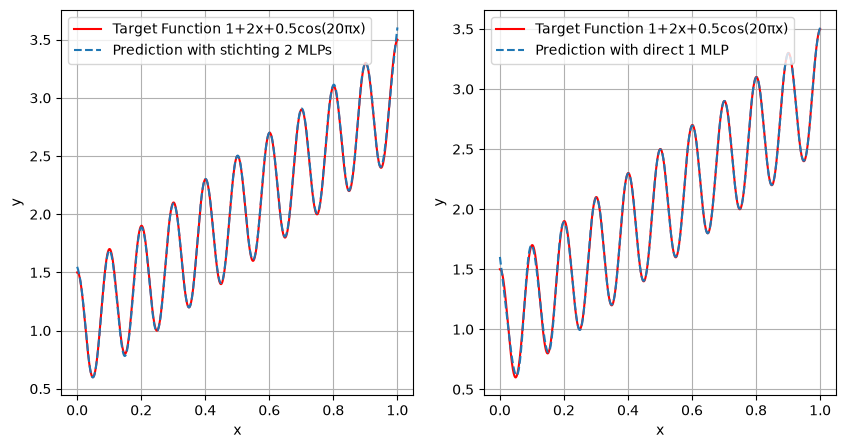

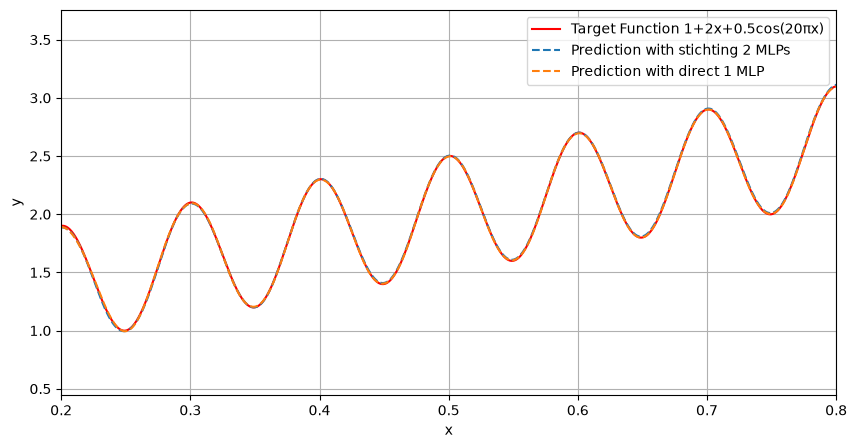

In [44]:
model_direct = MLP_Tanh(hidden_size=50, num_layers=3)
loss_direct = train_network(model_direct, x_train_tensor, y_train_final_tensor, epochs=20000, learning_rate = 0.001)

y_direct_pred = model_direct.forward(x_test_tensor).detach().numpy()

y_final_test = y_final(x_test)

fig, ax = plt.subplots(1,2, figsize=(10,5))
ax[0].plot(x_test, y_final_test, label='Target Function 1+2x+0.5cos(20πx)', color='red')
ax[0].plot(x_test, y_final_pred, label='Prediction with stichting 2 MLPs', linestyle='--')
ax[1].plot(x_test, y_final_test, label='Target Function 1+2x+0.5cos(20πx)', color='red')
ax[1].plot(x_test, y_direct_pred, label='Prediction with direct 1 MLP', linestyle='--')
ax[0].legend()
ax[0].set_xlabel('x')
ax[0].set_ylabel('y')
ax[0].grid(True)
ax[1].legend() 
ax[1].set_xlabel('x')
ax[1].set_ylabel('y')
ax[1].grid(True)

fig1, ax1 = plt.subplots(1,1, figsize=(10,5))
ax1.plot(x_test, y_final_test, label='Target Function 1+2x+0.5cos(20πx)', color='red')
ax1.plot(x_test, y_final_pred, label='Prediction with stichting 2 MLPs', linestyle='--')
ax1.plot(x_test, y_direct_pred, label='Prediction with direct 1 MLP', linestyle='--')
ax1.legend()
ax1.set_xlim(0.2,0.8)
ax1.set_xlabel('x')
ax1.set_ylabel('y')
ax1.grid(True)

plt.show()

## **4. Regularization**

### **4.1 L1 vs. L2 Penalties**

Take 40 evenly spaced points $x_{i}$ on $[0, 2π]$ with readings $y_{i} = sin(x_{i}) + ε_{i}$, $ε_{i} ∼ N(0, 0.1^{2})$. Fit $\hat{y}(x)=\sum_{j=1}^{100} w_{j}ϕ_{j}(x)$ with Gaussian bumps $ϕ_{j}(x) = exp(−(x − c_{j})^{2}/2ℓ^{2}$, centers $c_{j}$ evenly spaced on $[0, 2π]$ and $ℓ = 0.5$, by minimizing
$$
\frac{1}{40}\sum_{i=1}^{40}(\hat{y}(x_{i})-y_{i})^{2}+\lambda R(w), R(w)=\sum_{j}w_{j}^{2} (L2)  \space or \space  R(w)=\sum_{j}|w_{j}| (L1)
$$
Solve the L1 problem by soft thresholding or with a library solver.

a) Fit with no penalty. Plot the fit against $sin(x)$ and the readings. What happens between the readings, and why?

b) Fit with L2 and with L1 for $λ ∈ {10−4, 10−3, 10−2, 10−1}$. Report the RMSE against $sin(x)$ for each.

c) At $λ = 10^{−2}$, plot the 100 weights of the L2 and L1 fits. How many are exactly zero in each, and why?

### **Answer**

**a)** Fit without penalty

Because the 40 training points were added some noise to the target function, and the MLP was trained to fit the training data very well, including the noise. It is overfitting. 

Training loss: 0.005317
Test loss: 0.006772


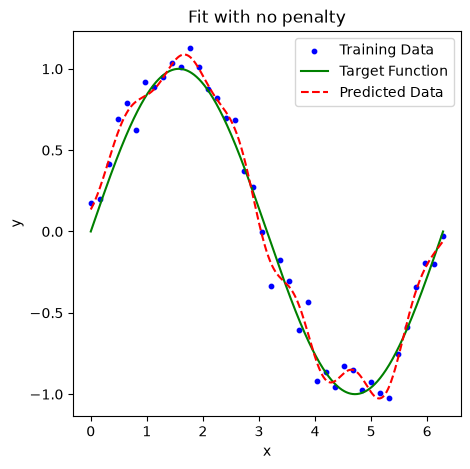

In [46]:
# SCI-ML HW#00: MLP function approximation

# 4.1 Regularization
# a)


import numpy as np
import matplotlib.pyplot as plt
import torch
import os
os.environ["KMP_DUPLICATE_LIB_OK"] = "TRUE"

class MLP(torch.nn.Module):
    def __init__(self, hidden_size = 100):
        super(MLP, self).__init__()
        self.hidden_size = hidden_size
        self.output = torch.nn.Linear(hidden_size, 1, bias=False)

    def forward(self, x):
        x = x - torch.linspace(0, 2*torch.pi, self.hidden_size)
        x = torch.exp(-x**2/(2*0.5**2))
        x = self.output(x)
        return x
        
def train_network(model, x_train, y_train, epochs = 20000, learning_rate = 0.001):
    optimizer = torch.optim.Adam(model.parameters(), lr=learning_rate)
    loss_fn = torch.nn.MSELoss()
    losses = []
    for epoch in range(epochs):
        optimizer.zero_grad()
        y_pred = model.forward(x_train)
        loss = loss_fn(y_pred, y_train)
        loss.backward()
        optimizer.step()
        losses.append(loss.item())
        #if epoch % 1000 == 0:
        #    print(f'Epoch{epoch+1}/{epochs}, Loss:{loss.item():.6f}')
    return losses

x_train = np.linspace(0,2*np.pi,40)
x_train_tensor = torch.tensor(x_train.reshape(-1,1), dtype = torch.float32)

np.random.seed(0)
y = lambda x: np.sin(x) + np.random.normal(0, 0.1, x.shape)
y_train = y(x_train)
y_train_tensor = torch.tensor(y_train.reshape(-1,1), dtype = torch.float32)

x_test = np.linspace(0, 2*np.pi, 1000)
x_test_tensor = torch.tensor(x_test.reshape(-1,1), dtype = torch.float32)
model = MLP(hidden_size=100)
losses = train_network(model, x_train_tensor, y_train_tensor, epochs=20000, learning_rate=0.001)
print(f'Training loss: {losses[-1]:.6f}')
y_pred = model.forward(x_test_tensor).detach().numpy()
print(f'Test loss: {np.mean((y_pred - np.sin(x_test).reshape(-1,1))**2):.6f}')

fig, ax = plt.subplots(1,1, figsize=(5,5))
ax.scatter(x_train, y_train, color='blue', label='Training Data', marker='o', s=10)
ax.plot(x_test, np.sin(x_test), color='green', label='Target Function')
ax.plot(x_test, y_pred, color='red', label='Predicted Data', linestyle='--')
ax.legend()
ax.set_xlabel('x')
ax.set_ylabel('y')
ax.set_title('Fit with no penalty')
plt.show()

**b)** 	Fit with L2 and L1 for $λ∈\{10^{-4},10^{-3},10^{-2},10^{-1} \}$

Training with L1 regularization, lambda=0.0001
Training loss: 0.006797
Test loss: 0.005355
Training with L2 regularization, lambda=0.0001
Training loss: 0.005972
Test loss: 0.005838
Training with L1 regularization, lambda=0.001
Training loss: 0.010998
Test loss: 0.003784
Training with L2 regularization, lambda=0.001
Training loss: 0.007247
Test loss: 0.004378
Training with L1 regularization, lambda=0.01
Training loss: 0.041599
Test loss: 0.003184
Training with L2 regularization, lambda=0.01
Training loss: 0.009945
Test loss: 0.003417
Training with L1 regularization, lambda=0.1
Training loss: 0.284248
Test loss: 0.052550
Training with L2 regularization, lambda=0.1
Training loss: 0.025825
Test loss: 0.002874


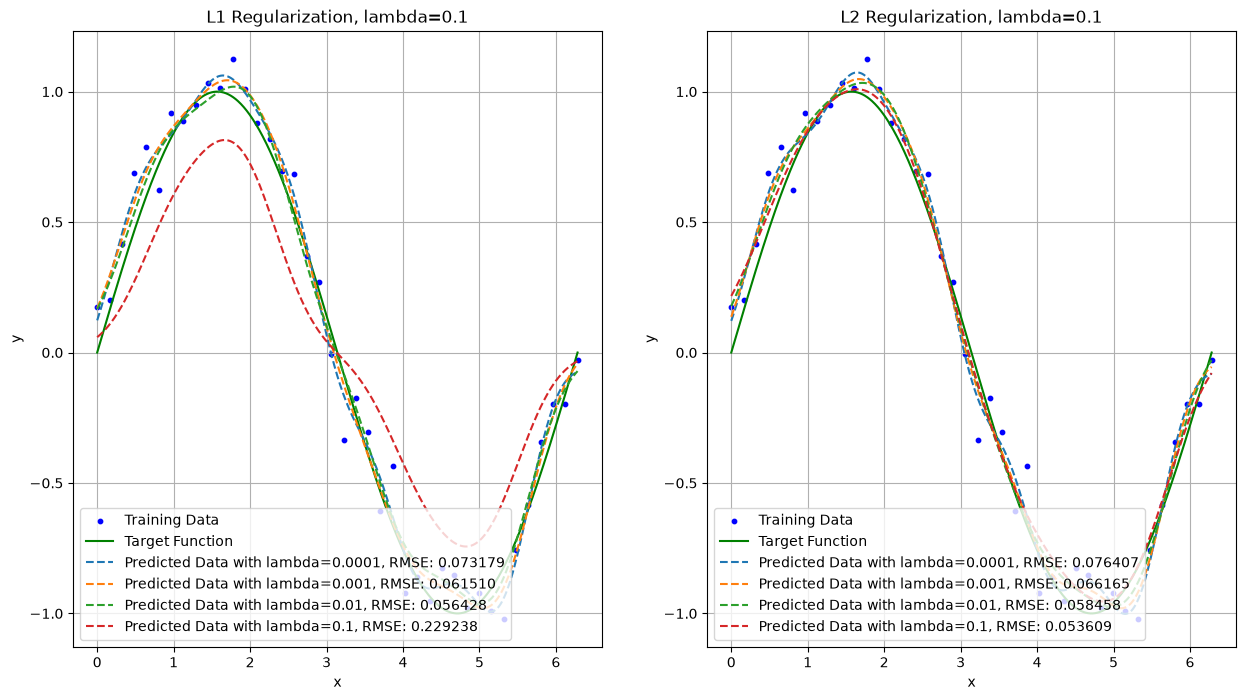

In [50]:
# SCI-ML HW#00: MLP function approximation

# 4.1 Regularization
# b)


import numpy as np
import matplotlib.pyplot as plt
import torch

class MLP(torch.nn.Module):
    def __init__(self, hidden_size = 100):
        super(MLP, self).__init__()
        self.hidden_size = hidden_size
        self.output = torch.nn.Linear(hidden_size, 1, bias=False)

    def forward(self, x):
        x = x - torch.linspace(0, 2*torch.pi, self.hidden_size)
        x = torch.exp(-x**2/(2*0.5**2))
        x = self.output(x)
        return x
        
def train_network_L1(model, x_train, y_train, epochs = 20000, learning_rate = 0.001, ld = 1e-4):
    optimizer = torch.optim.Adam(model.parameters(), lr=learning_rate)
    loss_fn = torch.nn.MSELoss()
    losses = []
    for epoch in range(epochs):
        optimizer.zero_grad()
        y_pred = model.forward(x_train)
        loss = loss_fn(y_pred, y_train) + ld * torch.sum(torch.abs(model.output.weight))
        loss.backward()
        optimizer.step()
        losses.append(loss.item())
        #if epoch % 1000 == 0:
        #    print(f'Epoch{epoch+1}/{epochs}, Loss:{loss.item():.6f}')
    return losses

def train_network_L2(model, x_train, y_train, epochs = 20000, learning_rate = 0.001, ld = 1e-4):
    optimizer = torch.optim.Adam(model.parameters(), lr=learning_rate)
    loss_fn = torch.nn.MSELoss()
    losses = []
    for epoch in range(epochs):
        optimizer.zero_grad()
        y_pred = model.forward(x_train)
        loss = loss_fn(y_pred, y_train) + ld * torch.sum(torch.square(model.output.weight))
        loss.backward()
        optimizer.step()
        losses.append(loss.item())
        #if epoch % 1000 == 0:
        #    print(f'Epoch{epoch+1}/{epochs}, Loss:{loss.item():.6f}')
    return losses

x_train = np.linspace(0,2*np.pi,40)
x_train_tensor = torch.tensor(x_train.reshape(-1,1), dtype = torch.float32)

np.random.seed(0)  # For reproducibility
y = lambda x: np.sin(x) + np.random.normal(0, 0.1, x.shape)
y_train = y(x_train)
y_train_tensor = torch.tensor(y_train.reshape(-1,1), dtype = torch.float32)

x_test = np.linspace(0, 2*np.pi, 1000)
x_test_tensor = torch.tensor(x_test.reshape(-1,1), dtype = torch.float32)
model = MLP(hidden_size=100)

fig, (ax1, ax2) = plt.subplots(1,2, figsize=(15,8))

ax1.scatter(x_train, y_train, color='blue', label='Training Data', marker='o', s=10)
ax1.plot(x_test, np.sin(x_test), color='green', label='Target Function')

ax2.scatter(x_train, y_train, color='blue', label='Training Data', marker='o', s=10)
ax2.plot(x_test, np.sin(x_test), color='green', label='Target Function')

for ld in [1e-4, 1e-3, 1e-2, 1e-1]:
    print(f'Training with L1 regularization, lambda={ld}')
    losses_L1 = train_network_L1(model, x_train_tensor, y_train_tensor, epochs=20000, learning_rate=0.001, ld=ld)
    print(f'Training loss: {losses_L1[-1]:.6f}')
    y_pred_L1 = model.forward(x_test_tensor).detach().numpy()
    print(f'Test loss: {np.mean((y_pred_L1 - np.sin(x_test).reshape(-1,1))**2):.6f}')

    ax1.plot(x_test, y_pred_L1, label=f'Predicted Data with lambda={ld}, RMSE: {np.sqrt(np.mean((y_pred_L1 - np.sin(x_test).reshape(-1,1))**2)):.6f}', linestyle='--')

    print(f'Training with L2 regularization, lambda={ld}')
    losses_L2 = train_network_L2(model, x_train_tensor, y_train_tensor, epochs=20000, learning_rate=0.001, ld=ld)
    print(f'Training loss: {losses_L2[-1]:.6f}')
    y_pred_L2 = model.forward(x_test_tensor).detach().numpy()
    print(f'Test loss: {np.mean((y_pred_L2 - np.sin(x_test).reshape(-1,1))**2):.6f}')

    ax2.plot(x_test, y_pred_L2, label=f'Predicted Data with lambda={ld}, RMSE: {np.sqrt(np.mean((y_pred_L2 - np.sin(x_test).reshape(-1,1))**2)):.6f}', linestyle='--')

ax1.legend(loc='lower left')
ax1.set_xlabel('x')
ax1.set_ylabel('y')
ax1.set_title(f'L1 Regularization, lambda={ld}')
ax1.grid(True)
ax2.legend(loc='lower left')
ax2.set_xlabel('x')
ax2.set_ylabel('y')
ax2.set_title(f'L2 Regularization, lambda={ld}')
ax2.grid(True)
plt.show()

**c)** At $λ=10^{-2}$, plot the 100 weights of the L2 and L1 fits.

For **L1** penalty: **48** weights are zero, while for **L2 0** weights are zero. Because L1 penalty tends to push the small weights to be zero. Considering the derivative of L1, 
$$
\frac{dL1(w)}{dw}=\lambda \frac{d|w|}{dw}=\begin{cases}
\lambda, & w>0 \\
-\lambda, & w<0
\end{cases}
$$
so even when a weight is small, its derivative can remain the value $\lambda$, which can continue push the weight to become zero. For L2, the derivative is 
$$
\frac{dL2(w)}{dw}=\frac{dλw^{2}}{dw}=2λw, 
$$
so L2 penalty’s derivative can make the weight to be small such that the gradient also becomes small

Training with L1 regularization, lambda=0.01
Training loss: 0.041608
Test loss: 0.003190
Number of zero weights in the output layer with L1 regularization: 48 out of 100
Training with L2 regularization, lambda=0.01
Training loss: 0.009943
Test loss: 0.003444
Number of zero weights in the output layer with L2 regularization: 0 out of 100


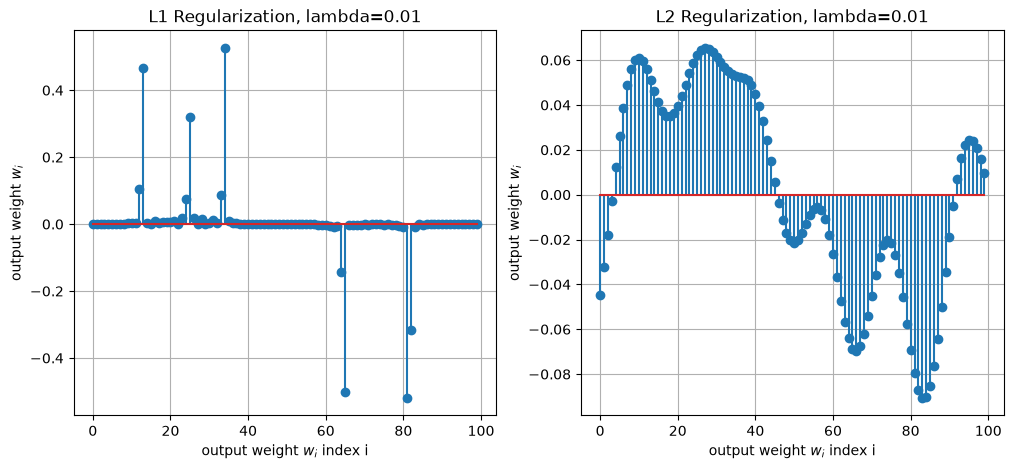

In [51]:
# SCI-ML HW#00: MLP function approximation

# 4.1 Regularization
# c)


import numpy as np
import matplotlib.pyplot as plt
import torch

class MLP(torch.nn.Module):
    def __init__(self, hidden_size = 100):
        super(MLP, self).__init__()
        self.hidden_size = hidden_size
        self.output = torch.nn.Linear(hidden_size, 1, bias=False)

    def forward(self, x):
        x = x - torch.linspace(0, 2*torch.pi, self.hidden_size)
        x = torch.exp(-x**2/(2*0.5**2))
        x = self.output(x)
        return x
        
def train_network_L1(model, x_train, y_train, epochs = 20000, learning_rate = 0.001, ld = 1e-4):
    optimizer = torch.optim.Adam(model.parameters(), lr=learning_rate)
    loss_fn = torch.nn.MSELoss()
    losses = []
    for epoch in range(epochs):
        optimizer.zero_grad()
        y_pred = model.forward(x_train)
        loss = loss_fn(y_pred, y_train) + ld * torch.sum(torch.abs(model.output.weight))
        loss.backward()
        optimizer.step()
        losses.append(loss.item())
        #if epoch % 1000 == 0:
        #    print(f'Epoch{epoch+1}/{epochs}, Loss:{loss.item():.6f}')
    return losses

def train_network_L2(model, x_train, y_train, epochs = 20000, learning_rate = 0.001, ld = 1e-4):
    optimizer = torch.optim.Adam(model.parameters(), lr=learning_rate)
    loss_fn = torch.nn.MSELoss()
    losses = []
    for epoch in range(epochs):
        optimizer.zero_grad()
        y_pred = model.forward(x_train)
        loss = loss_fn(y_pred, y_train) + ld * torch.sum(torch.square(model.output.weight))
        loss.backward()
        optimizer.step()
        losses.append(loss.item())
        #if epoch % 1000 == 0:
        #    print(f'Epoch{epoch+1}/{epochs}, Loss:{loss.item():.6f}')
    return losses

x_train = np.linspace(0,2*np.pi,40)
x_train_tensor = torch.tensor(x_train.reshape(-1,1), dtype = torch.float32)

np.random.seed(0)  # For reproducibility
y = lambda x: np.sin(x) + np.random.normal(0, 0.1, x.shape)
y_train = y(x_train)
y_train_tensor = torch.tensor(y_train.reshape(-1,1), dtype = torch.float32)

x_test = np.linspace(0, 2*np.pi, 1000)
x_test_tensor = torch.tensor(x_test.reshape(-1,1), dtype = torch.float32)
model = MLP(hidden_size=100)

fig, (ax1, ax2) = plt.subplots(1,2, figsize=(12,5))

print(f'Training with L1 regularization, lambda={1e-2}')
losses_L1 = train_network_L1(model, x_train_tensor, y_train_tensor, epochs=20000, learning_rate=0.001, ld=0.01)
print(f'Training loss: {losses_L1[-1]:.6f}')
y_pred_L1 = model.forward(x_test_tensor).detach().numpy()
print(f'Test loss: {np.mean((y_pred_L1 - np.sin(x_test).reshape(-1,1))**2):.6f}')

v = model.output.weight.detach().numpy().ravel()   # shape (n,)
count = np.sum(np.abs(v) <= 1e-3)
print(f'Number of zero weights in the output layer with L1 regularization: {count} out of {len(v)}')

ax1.stem(v)
ax1.set_xlabel("output weight $w_i$ index i")
ax1.set_ylabel("output weight $w_i$")
ax1.set_title(f'L1 Regularization, lambda={1e-2}')
ax1.grid(True)

print(f'Training with L2 regularization, lambda={1e-2}')
losses_L2 = train_network_L2(model, x_train_tensor, y_train_tensor, epochs=20000, learning_rate=0.001, ld=0.01)
print(f'Training loss: {losses_L2[-1]:.6f}')
y_pred_L2 = model.forward(x_test_tensor).detach().numpy()
print(f'Test loss: {np.mean((y_pred_L2 - np.sin(x_test).reshape(-1,1))**2):.6f}')

v = model.output.weight.detach().numpy().ravel()   # shape (n,)
count = np.sum(np.abs(v) <= 1e-3)
print(f'Number of zero weights in the output layer with L2 regularization: {count} out of {len(v)}')

ax2.stem(v)
ax2.set_xlabel("output weight $w_i$ index i")
ax2.set_ylabel("output weight $w_i$")
ax2.set_title(f'L2 Regularization, lambda={1e-2}')
ax2.grid(True)

plt.show()